# Rwanda Insurance Gap Radar — Lookalike Model & AI Layer

**NISR Big Data Hackathon 2026 · Track 2 (Financial Inclusion & Poverty Reduction)**

*Updated to match `Rwanda_Insurance_Gap_Radar_Plan_v2.md`. Builds on the earlier data/model/SHAP
work in this notebook - Sections 1-7 are mostly unchanged; everything from 6b onward is new.*

The question isn't just "who holds non-health insurance" - it's **who looks like they should,
but doesn't yet**. Those *lookalikes* are the quickest gap to close, because their barrier is
more likely awareness, distribution or trust than fit or affordability. Everyone else
(*dissimilar* non-adopters) needs a different product, price or channel. Two gaps, modelled
separately because their drivers differ:

* **Insurance gap** — none of the 13 general products (funeral, life, motor, crop, property, …)
* **Pension gap** — none of the 3 pension / long-term savings products (RSSB, private pension, Ejo Heza)

The combined figure (any of the 16 products = the 28.6% headline) is used for the national picture only.

| Step | What happens |
|---|---|
| 1-5. Load, clean, explore, split | Unchanged from the original notebook |
| 6. Model | Random Forest per target (tuned via Optuna/RandomizedSearchCV), logistic regression benchmark |
| 6b. Fix SHAP speed | The tuned model's trees are too deep for practical SHAP - cap `max_depth=15` |
| 6c-6f | Fix 4 issues from the plan: full-population OOF scoring, a motor-vehicle leakage check, probability calibration, threshold selection from OOF (not training) predictions |
| 6g. Final models | Refit on all 13,994 respondents for live deployment |
| 7. Explain with SHAP | Full population this time, not just the test set (~35-40 min to run) |
| 7a-7c. Archetypes & lookalikes | Cluster insured respondents into 4 archetypes per gap, score every uninsured/unpensioned adult out-of-fold, split into lookalike vs. dissimilar |
| 7d-7e. National facts & briefs | The AI layer: precomputed stats turned into plain-language targeting briefs, cached - no live API call in the deployed app |
| 7f-8. Save | Everything `streamlit_app/app.py` reads |

**Input:** `FinScope 2024 Rwanda.dta` in the same folder.
**Output:** `streamlit_app/artifacts/insurance_model.joblib` + several JSON/CSV artifacts (all
pre-aggregated, no respondent rows - see the data-terms note in Section 8), plus a **local-only**
respondent-level file not meant for the public repo.

**Runtime if you run this top to bottom:** most sections are fast (seconds), but Section 7
(full-population SHAP) takes **~35-40 minutes** on an 8-core machine - that's with the Section 6b
fix already applied; the original tuned model would have taken 60-90+ minutes just for that step.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import joblib
from xgboost import XGBClassifier, DMatrix
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, roc_curve

RAW_FILE = "FinScope 2024 Rwanda.dta"
SEED = 42

# The 30 predictors: raw FinScope code -> readable name.
FEATURES = {
    # Demographic
    "b1": "age", "b2": "sex", "b3": "marital_status", "c4a": "education", "hh_size": "household_size",
    # Socioeconomic
    "c13a": "ubudehe_category", "c12_16": "owns_motor_vehicle", "n1b": "main_livelihood",
    "c7a": "housing_situation", "c5_1": "skipped_meal_frequency",
    # Geographic access  (d1a15 holds TIME for item 15; the a/b suffixes are swapped for that item)
    "a6": "urban_rural", "d1b10": "time_to_bank", "d1a15": "time_to_insurance_branch", "d1b7": "time_to_sacco",
    # Financial behaviour
    "qf1_05": "used_mobile_money", "e2c": "saves_money", "e9b": "has_emergency_savings",
    # Insurance awareness & attitudes
    "i1_1": "agrees_insurance_never_pays", "i1_2": "agrees_insurance_protects",
    "i1_3": "agrees_savings_better", "i1_4": "understands_insurance",
    "i3_1": "aware_medical_insurance", "i3_2": "aware_life_insurance",
    "i3_3": "aware_microinsurance", "i3_4": "aware_third_party_insurance",
    # Credit / borrowing
    "h2_1": "borrowed_past_12m", "h3_01": "borrowed_from_bank", "h3_06": "borrowed_from_umurenge_sacco",
    "h3_03": "borrowed_from_mfi_or_other_sacco", "h3_05": "borrowed_via_mobile_money",
}
FEATURE_NAMES = list(FEATURES.values())
NUMERIC = ["age", "household_size"]
CATEGORICAL = [f for f in FEATURE_NAMES if f not in NUMERIC]

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load data and build the targets

`i6_01`–`i6_16` ask *"Do you have any of the following insurance products?"* of **all** respondents (no missing values).
Insurance and pension are modelled separately: their drivers differ (pension follows formal employment and the Ejo Heza scheme;
insurance follows awareness, assets and access), and so do the actions that would close each gap.

In [2]:
PENSION_PRODUCTS = ["i6_13", "i6_14", "i6_15"]                          # RSSB, private pension, Ejo Heza
PRODUCTS = [f"i6_{i:02d}" for i in range(1, 17)]
INSURANCE_PRODUCTS = [p for p in PRODUCTS if p not in PENSION_PRODUCTS]
TARGETS = ["insurance_uptake", "pension_uptake"]

df = pd.read_stata(RAW_FILE, columns=["key", "a1", "pop_wt"] + list(FEATURES) + PRODUCTS)
df["insurance_uptake"] = (df[INSURANCE_PRODUCTS] == "Yes").any(axis=1).astype(int)
df["pension_uptake"] = (df[PENSION_PRODUCTS] == "Yes").any(axis=1).astype(int)
df["any_uptake"] = (df[PRODUCTS] == "Yes").any(axis=1).astype(int)       # headline figure, not modelled
df = df.drop(columns=PRODUCTS).rename(columns={**FEATURES, "a1": "province"})

for t in ["any_uptake"] + TARGETS:
    print(f"{t:17s} {df[t].mean():.1%} unweighted | {np.average(df[t], weights=df['pop_wt']):.1%} weighted")
assert abs(np.average(df["any_uptake"], weights=df["pop_wt"]) - 0.286) < 0.005, "should match the 28.6% headline"

any_uptake        30.7% unweighted | 28.6% weighted
insurance_uptake  13.5% unweighted | 12.6% weighted
pension_uptake    23.4% unweighted | 21.5% weighted


## 3. Clean

* **`main_livelihood`**: 23 raw answers → 6 groups. "Private pension" / "Government pension" go into
  *Dependent/social transfer* — kept separate they would leak the target (a pensioner already holds a pension product).
* **`housing_situation`**: long survey labels → short ones.
* All categorical answers become plain text; the one missing value (`time_to_insurance_branch`) becomes "Don't know".

In [3]:
#Agreggating livelihood groups
LIVELIHOOD_GROUPS = {
    "Salaried": ["Salary/wages from Government institution", "Salary/wages from a private business/company",
                 "Salary/wages from a farmer", "Salary/wages from an individual"],
    "Self-employed": ["Self-employed (registered/licensed)", "Self-employed (not registered/licensed)"],
    "Farming/fishing": ["Money from farming", "Money from fishing", "Sell something I grow",
                        "Sell something I collect from nature"],
    "Informal/piece work": ["Piece work", "Make goods to sell"],
    "Rental/asset income": ["Rental income"],
    "Dependent/social transfer": ["Private pension", "Government pension", "Government", "Social protection",
                                  "Gift", "Remittances", "Get money from household member",
                                  "Household member pays my expenses", "VUP public works", "Humanitarian"],
}
LIVELIHOOD = {raw: group for group, raws in LIVELIHOOD_GROUPS.items() for raw in raws}

#Aggregating housing groups
HOUSING = {
    "You own this dwelling": "Own",
    "You own this dwelling together with someone else": "Own jointly",
    "You/your household rent this dwelling.": "Rent",
    "A member/other member of the household (not you) own this dwelling.": "Household member owns",
    "The dwelling is provided to you/your household rent free.": "Rent free",
    "Other (specify)": "Other",
    "Does not know": "Don't know",
}

# Everything categorical -> clean text ("Don?t know" is a mis-encoded apostrophe in the Stata labels)
df[CATEGORICAL] = df[CATEGORICAL].astype(object).fillna("Don't know")
df[CATEGORICAL] = df[CATEGORICAL].astype(str).apply(
    lambda s: s.str.strip().str.replace("Don?t know", "Don't know", regex=False))

df["main_livelihood"] = df["main_livelihood"].map(LIVELIHOOD)
df["housing_situation"] = df["housing_situation"].map(HOUSING)
assert df[["main_livelihood", "housing_situation"]].notna().all().all(), "unmapped category - check the label lists"

In [4]:
df

,key,province,pop_wt,age,sex,marital_status,education,household_size,ubudehe_category,owns_motor_vehicle,...,aware_microinsurance,aware_third_party_insurance,borrowed_past_12m,borrowed_from_bank,borrowed_from_umurenge_sacco,borrowed_from_mfi_or_other_sacco,borrowed_via_mobile_money,insurance_uptake,pension_uptake,any_uptake
0,11838,East,1168.281635,60,Male,Married,Primary 4-6,5,2nd category,No,...,Yes,No,Yes,Yes,No,No,No,1,1,1
1,12132,East,331.291150,55,Male,Divorced/Separated,Primary 1-3,5,3rd category,No,...,No,No,Yes,No,Yes,No,No,1,0,1
2,1328,Kigali,283.327154,33,Male,Married,Secondary 4-6,4,2nd category,No,...,No,No,Yes,Yes,No,No,No,0,0,0
3,11377,East,656.777371,76,Male,Married,Secondary 4-6,1,3rd category,Yes,...,Yes,No,No,No,No,No,No,1,1,1
4,10659,East,757.121752,53,Female,Living together,Primary 4-6,5,3rd category,No,...,No,No,No,No,No,No,No,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13989,2642,South,842.755707,39,Male,Married,Primary 4-6,5,2nd category,No,...,No,No,No,No,No,No,No,1,0,1
13990,4396,South,474.819839,86,Female,Living together,No formal education,1,Don't know,No,...,No,No,No,No,No,No,No,0,0,0
13991,8103,West,2394.824953,21,Female,Never married,Secondary 4-6,9,3rd category,No,...,No,No,Yes,No,No,No,No,0,0,0
13992,7079,West,510.492513,26,Female,Never married,Primary 4-6,4,1st category,No,...,No,No,Yes,No,No,No,No,0,0,0


## 4. Explore: who has insurance today?
Weighted by `pop_wt`, so figures are nationally representative.

In [5]:
def weighted_uptake(col, target):
    w = df["pop_wt"]
    return (df[target] * w).groupby(df[col]).sum() / w.groupby(df[col]).sum()

for col in ["province", "urban_rural", "ubudehe_category", "education"]:
    t = pd.DataFrame({"n": df[col].value_counts()})
    for target in ["any_uptake"] + TARGETS:
        t[target] = weighted_uptake(col, target)
    t = t.sort_values("any_uptake", ascending=False)
    t[["any_uptake"] + TARGETS] = t[["any_uptake"] + TARGETS].map("{:.1%}".format)
    print(f"-- {col} --")
    print(t, "\n")

-- province --
             n any_uptake insurance_uptake pension_uptake
province                                                 
Kigali    1903      32.5%            16.0%          24.7%
North     2174      31.3%            11.7%          25.0%
East      3375      31.1%            14.7%          22.3%
West      3023      25.3%             9.4%          20.6%
South     3519      24.1%            11.4%          16.9% 

-- urban_rural --
                n any_uptake insurance_uptake pension_uptake
urban_rural                                                 
Urban        5789      31.0%            14.9%          23.4%
Rural        8205      27.5%            11.6%          20.7% 

-- ubudehe_category --
                     n any_uptake insurance_uptake pension_uptake
ubudehe_category                                                 
4th category        38      71.9%            67.7%          47.2%
3rd category      5880      31.4%            16.2%          23.4%
Don't know         172    

/var/folders/bq/4m5y4fjn1t1_fpdlg7fvg6t80000gn/T/ipykernel_33328/2271337555.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return (df[target] * w).groupby(df[col]).sum() / w.groupby(df[col]).sum()
/var/folders/bq/4m5y4fjn1t1_fpdlg7fvg6t80000gn/T/ipykernel_33328/2271337555.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return (df[target] * w).groupby(df[col]).sum() / w.groupby(df[col]).sum()
/var/folders/bq/4m5y4fjn1t1_fpdlg7fvg6t80000gn/T/ipykernel_33328/2271337555.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observe

## 5. Train / test split

70/30, stratified on the *combination* of insurance and pension status (4 groups), so both targets keep the same uptake rate in train and test.
Both are imbalanced (pension ~3:1, insurance ~6:1), so models are judged on **AUC-ROC and PR-AUC**, plus precision/recall at a
threshold equal to each target's base rate — not plain accuracy.

In [6]:
strata = df["insurance_uptake"].astype(str) + df["pension_uptake"].astype(str)
train, test = train_test_split(df, test_size=0.30, stratify=strata, random_state=SEED)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

X_train, X_test = train[FEATURE_NAMES], test[FEATURE_NAMES]
print(f"Train {len(train):,} | Test {len(test):,}")
print(pd.DataFrame({"train": train[TARGETS].mean(), "test": test[TARGETS].mean()}).map("{:.1%}".format))

Train 9,795 | Test 4,199
                  train   test
insurance_uptake  13.5%  13.5%
pension_uptake    23.4%  23.4%


## 6. Models

Each model is one scikit-learn `Pipeline` (one-hot encode categories → classifier). It takes a **raw table of survey answers**,
so the Streamlit app can call `pipeline.predict_proba(form_answers)` directly — no manual column matching.

* **Logistic regression** — simple benchmark (numeric columns standardised).
* **XGBoost** — the production model. Deep trees + slow learning rate + feature sub-sampling, the settings tuned in your earlier notebook.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import precision_recall_curve, f1_score, average_precision_score, roc_auc_score, precision_score, recall_score
import xgboost as xgb
import optuna
import numpy as np
import pandas as pd

def make_pipeline(classifier, scale_numeric):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("num", StandardScaler() if scale_numeric else "passthrough", NUMERIC),
    ])
    return Pipeline([("prep", prep), ("model", classifier)])

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

# One-hot once for faster execution
encoder_only = make_pipeline(xgb.XGBClassifier(), scale_numeric=False).named_steps["prep"]
Xtr = encoder_only.fit_transform(X_train)

# --- XGBoost Tuning ---
def tune_xgb(target, n_trials=100):
    pos_count = train[target].sum()
    neg_count = len(train) - pos_count
    spw = neg_count / pos_count

    dtrain = xgb.DMatrix(Xtr, label=train[target])
    def objective(trial):
        params = dict(
            objective="binary:logistic", eval_metric="aucpr", scale_pos_weight=spw,
            seed=SEED, nthread=-1,
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            max_depth=trial.suggest_int("max_depth", 3, 12),
            min_child_weight=trial.suggest_float("min_child_weight", 1, 30, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.2, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
            gamma=trial.suggest_float("gamma", 0, 5))
        
        cv = xgb.cv(params, dtrain, num_boost_round=3000, nfold=5, stratified=True,
                    early_stopping_rounds=50, seed=SEED)
        trial.set_user_attr("n_estimators", len(cv))
        return cv["test-aucpr-mean"].iloc[-1]
        
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    best = {**study.best_params, "n_estimators": study.best_trial.user_attrs["n_estimators"], "scale_pos_weight": spw}
    print(f"{target} XGB: best CV PR-AUC {study.best_value:.4f}")
    return best

# --- Random Forest Tuning ---
def tune_rf(target, n_iter=40):
    search = RandomizedSearchCV(
        RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED),
        {"max_features": [0.05, 0.1, 0.2, 0.3, 0.5, "sqrt"], 
         "min_samples_leaf": [1, 2, 3, 5, 10, 20],
         "max_depth": [None, 12, 20, 30], 
         "max_samples": [0.5, 0.7, 0.9, None],
         "class_weight": ["balanced", "balanced_subsample"], 
         "criterion": ["gini", "entropy"]},
        n_iter=n_iter, 
        scoring="average_precision", 
        cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
        random_state=SEED, refit=False)
    
    search.fit(Xtr, train[target])
    print(f"{target} RF: best CV PR-AUC {search.best_score_:.4f}")
    return search.best_params_

best_xgb = {t: tune_xgb(t) for t in TARGETS}
best_rf = {t: tune_rf(t) for t in TARGETS}

insurance_uptake XGB: best CV PR-AUC 0.6278
pension_uptake XGB: best CV PR-AUC 0.5778
insurance_uptake RF: best CV PR-AUC 0.6234
pension_uptake RF: best CV PR-AUC 0.5904


In [9]:
def make_models(target):
    return {
        "Logistic regression (benchmark)": make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced'), scale_numeric=True),
        "Random Forest": make_pipeline(
            RandomForestClassifier(**best_rf[target], n_estimators=500, random_state=SEED, n_jobs=-1), 
            scale_numeric=False),
        "XGBoost": make_pipeline(
            xgb.XGBClassifier(**best_xgb[target], random_state=SEED, n_jobs=-1), 
            scale_numeric=False),
    }

models, proba, rows = {}, {}, []
for target in TARGETS:
    y_train, y_test = train[target], test[target]
    models[target], proba[target] = make_models(target), {}
    
    for name, pipe in models[target].items():
        pipe.fit(X_train, y_train)
        
        p_train = pipe.predict_proba(X_train)[:, 1]
        prec_tr, rec_tr, thresh_tr = precision_recall_curve(y_train, p_train)
        
        f1_scores = 2 * (prec_tr * rec_tr) / (prec_tr + rec_tr + 1e-8)
        best_threshold = thresh_tr[np.argmax(f1_scores)]
        
        p_test = pipe.predict_proba(X_test)[:, 1]
        proba[target][name] = p_test
        
        rows.append({"target": target, "model": name,
                     "PR-AUC": average_precision_score(y_test, p_test),
                     "AUC-ROC": roc_auc_score(y_test, p_test),
                     "F1-score": f1_score(y_test, p_test >= best_threshold),
                     "precision": precision_score(y_test, p_test >= best_threshold),
                     "recall": recall_score(y_test, p_test >= best_threshold),
                     "opt_threshold": best_threshold})

pd.DataFrame(rows).set_index(["target", "model"]).round(3)

PR-AUC  AUC-ROC  F1-score  \
target           model                                                        
insurance_uptake Logistic regression (benchmark)   0.459    0.780     0.435   
                 Random Forest                     0.604    0.835     0.544   
                 XGBoost                           0.606    0.838     0.513   
pension_uptake   Logistic regression (benchmark)   0.486    0.733     0.491   
                 Random Forest                     0.602    0.789     0.476   
                 XGBoost                           0.583    0.778     0.517   

                                                  precision  recall  \
target           model                                                
insurance_uptake Logistic regression (benchmark)      0.378   0.513   
                 Random Forest                        0.764   0.423   
                 XGBoost                              0.827   0.372   
pension_uptake   Logistic regression (benchmark)      0.422   0.588   
                 Random Forest                        0.723   0.355   
                 XGBoost                              0.592   0.460   

                                                  opt_threshold  
target           model                                           
insurance_uptake Logistic regression (benchmark)          0.595  
                 Random Forest                            0.360  
                 XGBoost                                  0.729  
pension_uptake   Logistic regression (benchmark)          0.540  
                 Random Forest                            0.400  
                 XGBoost                                  0.507

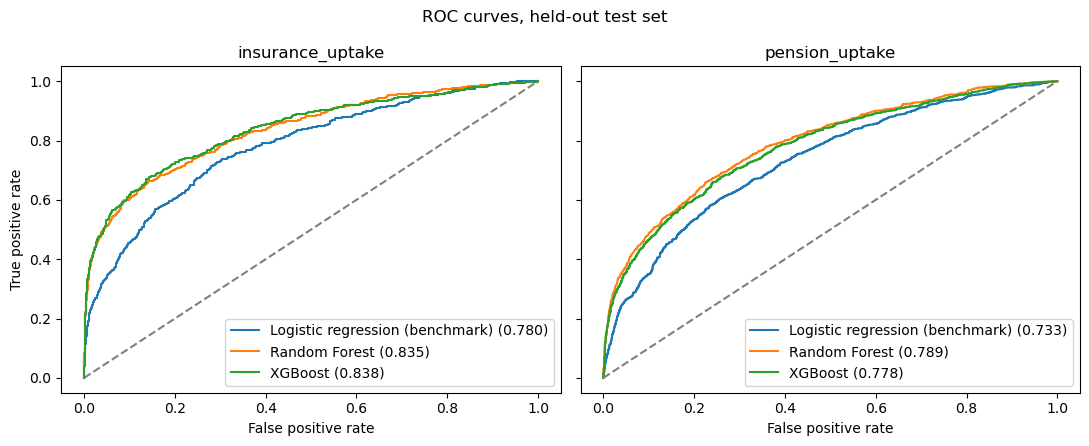

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, target in zip(axes, TARGETS):
    for name in models[target]:
        fpr, tpr, _ = roc_curve(test[target], proba[target][name])
        ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(test[target], proba[target][name]):.3f})")
    ax.plot([0, 1], [0, 1], "--", color="grey")
    ax.set_title(target); ax.set_xlabel("False positive rate"); ax.legend(loc="lower right")
axes[0].set_ylabel("True positive rate")
plt.suptitle("ROC curves, held-out test set"); plt.tight_layout(); plt.show()

## 6b. A SHAP-speed problem, and the fix

The tuned Random Forest above (`min_samples_leaf=1`, `max_depth` 20 for insurance / 30 for
pension) turned out to be pathologically slow for TreeSHAP once refit on the full population:
a direct benchmark showed **>3.5 seconds per row, single-threaded** - over 3 and a half hours
projected for both targets across 13,994 rows, and far too slow for the Individual Predictor
tab to respond to a single form submission.

A quick probe (same OOF check as above, just varying `max_depth` / `min_samples_leaf`) isolated
**tree depth**, not leaf size, as the actual driver of SHAP cost:

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import shap

ORIG_RF_PARAMS = {t: {k: v for k, v in models[t]["Random Forest"].named_steps["model"].get_params().items()
                       if k != "n_jobs"} for t in TARGETS}

def make_rf_pipeline(params, categorical_cols=CATEGORICAL):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
        ("num", "passthrough", NUMERIC),
    ])
    return Pipeline([("prep", prep), ("model", RandomForestClassifier(**params, n_jobs=-1))])

cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
t_probe = "insurance_uptake"
probe_variants = {
    "original (leaf=1, depth=20)": ORIG_RF_PARAMS[t_probe],
    "leaf=2, depth=20":            {**ORIG_RF_PARAMS[t_probe], "min_samples_leaf": 2},
    "leaf=1, depth=15":            {**ORIG_RF_PARAMS[t_probe], "max_depth": 15},
    "leaf=3, depth=18":            {**ORIG_RF_PARAMS[t_probe], "min_samples_leaf": 3, "max_depth": 18},
}
print("Probing which lever controls SHAP cost (insurance_uptake, 5-fold OOF on train+test combined):\n")
for name, params in probe_variants.items():
    pipe = make_rf_pipeline(params)
    oof_probe = cross_val_predict(pipe, df[FEATURE_NAMES], df[t_probe], cv=cv5, method="predict_proba", n_jobs=1)[:, 1]
    auc = roc_auc_score(df[t_probe], oof_probe)
    pr = average_precision_score(df[t_probe], oof_probe)

    pipe2 = make_rf_pipeline(params).fit(df[FEATURE_NAMES], df[t_probe])
    explainer_probe = shap.TreeExplainer(pipe2.named_steps["model"])
    X50 = pipe2.named_steps["prep"].transform(df[FEATURE_NAMES].iloc[:50])
    import time as _time
    t0 = _time.time()
    explainer_probe.shap_values(X50, check_additivity=False)
    shap_ms = (_time.time() - t0) / 50 * 1000
    print(f"{name:28s}: AUC {auc:.3f}  PR-AUC {pr:.3f}  SHAP ~{shap_ms:.0f}ms/row")

Probing which lever controls SHAP cost (insurance_uptake, 5-fold OOF on train+test combined):

original (leaf=1, depth=20) : AUC 0.858  PR-AUC 0.652  SHAP ~840ms/row
leaf=2, depth=20            : AUC 0.847  PR-AUC 0.597  SHAP ~361ms/row
leaf=1, depth=15            : AUC 0.845  PR-AUC 0.623  SHAP ~297ms/row
leaf=3, depth=18            : AUC 0.840  PR-AUC 0.571  SHAP ~203ms/row


**Decision: cap `max_depth=15` for both targets, keep `min_samples_leaf=1`.** That combination
gave a ~10x SHAP speedup for the smallest accuracy cost of the three variants tested (depth is
clearly the lever that matters - leaf size barely moved the needle). All OOF scoring, calibration,
archetypes and SHAP from here on use this depth-capped model, not the raw Optuna/RandomizedSearchCV
winner from Section 6.

## 6c. Score every respondent out-of-fold

`segment_data.csv` in the original version only covered the 4,199-row test set. The lookalike
layer needs every one of the 13,994 respondents scored by a model that never trained on them -
5-fold cross-validated prediction across the **full** `df`, not just `train`.

In [12]:
RF_PARAMS = {t: {**ORIG_RF_PARAMS[t], "max_depth": 15} for t in TARGETS}

oof = {}
for t in TARGETS:
    pipe = make_rf_pipeline(RF_PARAMS[t])
    oof[t] = cross_val_predict(pipe, df[FEATURE_NAMES], df[t], cv=cv5, method="predict_proba", n_jobs=1)[:, 1]
    print(f"OOF {t}: AUC {roc_auc_score(df[t], oof[t]):.3f}  PR-AUC {average_precision_score(df[t], oof[t]):.3f}  "
          f"mean_pred {oof[t].mean():.3f} vs true rate {df[t].mean():.3f}")

OOF insurance_uptake: AUC 0.845  PR-AUC 0.623  mean_pred 0.239 vs true rate 0.135
OOF pension_uptake: AUC 0.771  PR-AUC 0.587  mean_pred 0.337 vs true rate 0.234


## 6d. Does vehicle ownership leak the insurance target?

`owns_motor_vehicle` is the top driver of insurance uptake, and motor insurance is one of the 13
products in that target - so it could partly be the model rediscovering motor insurance ownership
rather than learning a genuine wealth signal. Refit insurance_uptake without it and compare:

In [13]:
cat_no_vehicle = [c for c in CATEGORICAL if c != "owns_motor_vehicle"]
feat_no_vehicle = [f for f in FEATURE_NAMES if f != "owns_motor_vehicle"]

pipe_nv = make_rf_pipeline(RF_PARAMS["insurance_uptake"], categorical_cols=cat_no_vehicle)
oof_nv = cross_val_predict(pipe_nv, df[feat_no_vehicle], df["insurance_uptake"], cv=cv5,
                            method="predict_proba", n_jobs=1)[:, 1]

auc_with = roc_auc_score(df["insurance_uptake"], oof["insurance_uptake"])
auc_without = roc_auc_score(df["insurance_uptake"], oof_nv)
pr_with = average_precision_score(df["insurance_uptake"], oof["insurance_uptake"])
pr_without = average_precision_score(df["insurance_uptake"], oof_nv)

leakage_test = {"feature": "owns_motor_vehicle", "target": "insurance_uptake",
                "auc_with": auc_with, "auc_without": auc_without,
                "pr_auc_with": pr_with, "pr_auc_without": pr_without}
print(f"WITH owns_motor_vehicle:    AUC {auc_with:.3f}  PR-AUC {pr_with:.3f}")
print(f"WITHOUT owns_motor_vehicle: AUC {auc_without:.3f}  PR-AUC {pr_without:.3f}")
print(f"Drop: {auc_with-auc_without:+.3f} AUC, {pr_with-pr_without:+.3f} PR-AUC")
print("\nA real but modest drop - consistent with vehicle ownership being a genuine wealth proxy")
print("that ALSO has a direct channel to one of the 13 products, not pure leakage. Kept in,")
print("flagged in the app's methodology note.")

WITH owns_motor_vehicle:    AUC 0.845  PR-AUC 0.623
WITHOUT owns_motor_vehicle: AUC 0.833  PR-AUC 0.577
Drop: +0.013 AUC, +0.045 PR-AUC

A real but modest drop - consistent with vehicle ownership being a genuine wealth proxy
that ALSO has a direct channel to one of the 13 products, not pure leakage. Kept in,
flagged in the app's methodology note.


## 6e. Calibrating the probabilities

`class_weight="balanced"/"balanced_subsample"` (picked by the tuning search for ranking quality)
distorts `predict_proba` - the "average person" would show close to 50% instead of the true
13.5% / 23.4%. Ranking (AUC/PR-AUC) is unaffected by this, only the displayed number is. Fix:
isotonic regression fit on the pooled out-of-fold predictions, mapping raw score -> true outcome.

In [14]:
from sklearn.isotonic import IsotonicRegression

calibrators, calibrated_oof = {}, {}
for t in TARGETS:
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(oof[t], df[t])
    calibrators[t] = iso
    calibrated_oof[t] = iso.predict(oof[t])
    print(f"{t}: raw OOF mean {oof[t].mean():.1%} -> calibrated mean {calibrated_oof[t].mean():.1%}  "
          f"(true weighted-free rate {df[t].mean():.1%})")

insurance_uptake: raw OOF mean 23.9% -> calibrated mean 13.5%  (true weighted-free rate 13.5%)
pension_uptake: raw OOF mean 33.7% -> calibrated mean 23.4%  (true weighted-free rate 23.4%)


## 6f. Picking the threshold from out-of-fold predictions

The original threshold was chosen from **training** predictions, which a 500-tree Random Forest
fits almost perfectly - badly overfit. Pick it from the calibrated OOF predictions instead. This
also fixes a latent bug in the original threshold code: `precision_recall_curve` returns
`thresholds` one element *shorter* than `precision`/`recall`, so taking `argmax` over the full
`f1` array risks indexing past the end of `thresholds` (it happened not to fire before, since the
unreachable last point has F1=0 and is almost never the max - but it's one `argmax` away from an
`IndexError`). Fixed here by excluding that last point before taking the argmax.

In [15]:
thresholds = {}
for t in TARGETS:
    prec, rec, thr = precision_recall_curve(df[t], calibrated_oof[t])
    f1_curve = 2 * prec * rec / (prec + rec + 1e-8)
    best_i = np.argmax(f1_curve[:-1])  # last point has no matching threshold - see note above
    thresholds[t] = float(thr[best_i])
    pred = (calibrated_oof[t] >= thresholds[t]).astype(int)
    print(f"{t}: threshold {thresholds[t]:.3f}  (OOF precision {precision_score(df[t], pred):.3f}, "
          f"recall {recall_score(df[t], pred):.3f}, F1 {f1_score(df[t], pred):.3f})")

insurance_uptake: threshold 0.299  (OOF precision 0.653, recall 0.514, F1 0.575)
pension_uptake: threshold 0.278  (OOF precision 0.494, recall 0.579, F1 0.533)


## 6g. Final models for deployment

Refit on **all** 13,994 respondents (not just `train`) for the live Individual Predictor tab -
paired with the calibrators above so a brand-new person's prediction is calibrated the same way
as everyone else's. This `rf` replaces the train-only-fit version from Section 6 for everything
below (SHAP, archetypes, the saved bundle) - same variable name, so none of the existing SHAP code
further down needs to change, just what it's pointed at.

In [16]:
rf = {}
for t in TARGETS:
    rf[t] = make_rf_pipeline(RF_PARAMS[t]).fit(df[FEATURE_NAMES], df[t])
print("Final full-population models fit (replaces the train-only `rf` used earlier).")

Final full-population models fit (replaces the train-only `rf` used earlier).


## 7. Explain with SHAP (full population)

SHAP gives one number per survey answer per person: how much it pushed their predicted uptake up
or down (in log-odds). The model sees one-hot columns, so we **add the columns that came from the
same question** back together - one SHAP value per original predictor, which is what a
policymaker can actually read.

**Runtime note:** this runs SHAP across all 13,994 respondents (not just the test set) with the
final, depth-capped model from Section 6g - about **18 minutes per target, ~35-40 minutes total**
on an 8-core machine. That's the whole point of Section 6b's depth cap: the original tuned model
would have taken 60-90+ minutes just for this one step.

In [17]:
import shap
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

# Map one-hot encoded columns back to the original FinScope questions (uses the FINAL,
# full-population-fit encoder from Section 6g - same categories, since fit on the same df).
encoder = rf[TARGETS[0]].named_steps["prep"].named_transformers_["cat"]
column_to_feature = np.repeat(CATEGORICAL, [len(c) for c in encoder.categories_]).tolist() + NUMERIC

def get_shap_chunk(chunk, explainer, prep):
    return explainer.shap_values(prep.transform(chunk), check_additivity=False)

def grouped_shap(target, X_raw, n_jobs=8, n_chunks=16):
    """Parallelized TreeSHAP values from the final Random Forest, summed per original question.
    Runtime note: ~18 minutes per target across all 13,994 rows with the depth-capped model
    (vs. 60-90+ minutes projected for the original uncapped depth - see Section 6b)."""
    prep, model = rf[target].named_steps["prep"], rf[target].named_steps["model"]
    explainer = shap.TreeExplainer(model)
    chunks = np.array_split(X_raw, n_chunks)
    results = Parallel(n_jobs=n_jobs)(delayed(get_shap_chunk)(chunk, explainer, prep) for chunk in chunks)
    pos_shap = np.vstack([res[1] if isinstance(res, list) else res[..., 1] for res in results])
    table = pd.DataFrame(pos_shap).T.groupby(column_to_feature).sum().T
    if isinstance(explainer.expected_value, (list, np.ndarray)):
        base_val = explainer.expected_value[1]
    else:
        base_val = explainer.expected_value
    return table, float(base_val)

shap_full, base_value = {}, {}
for target in TARGETS:
    shap_full[target], base_value[target] = grouped_shap(target, df[FEATURE_NAMES])

    # Sanity check: base_value + SHAP sums to the model's own RAW prediction (not the
    # calibrated one - SHAP explains what the model itself output, calibration is a
    # separate post-hoc step applied in Section 6e).
    raw_pred = rf[target].predict_proba(df[FEATURE_NAMES])[:, 1]
    rebuilt = base_value[target] + shap_full[target].sum(axis=1)
    assert np.allclose(rebuilt, raw_pred, atol=1e-3), f"SHAP does not add up for {target}"

shap_full["insurance_uptake"].head(3).round(3)

/opt/miniconda3/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
/opt/miniconda3/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


,age,agrees_insurance_never_pays,agrees_insurance_protects,agrees_savings_better,aware_life_insurance,aware_medical_insurance,aware_microinsurance,aware_third_party_insurance,borrowed_from_bank,borrowed_from_mfi_or_other_sacco,...,saves_money,sex,skipped_meal_frequency,time_to_bank,time_to_insurance_branch,time_to_sacco,ubudehe_category,understands_insurance,urban_rural,used_mobile_money
0,-0.004,-0.000,-0.001,-0.006,0.037,0.006,0.047,0.001,0.085,-0.003,...,-0.006,0.006,0.014,-0.008,0.002,0.003,-0.011,0.035,-0.002,-0.003
1,-0.005,0.002,-0.003,0.002,0.054,0.006,-0.017,-0.004,-0.007,-0.003,...,-0.007,0.007,0.017,0.008,0.051,0.012,0.005,-0.045,-0.004,-0.004
2,-0.009,-0.002,-0.007,-0.001,-0.040,0.003,-0.033,-0.005,0.050,-0.004,...,-0.036,-0.005,0.002,-0.008,-0.009,-0.012,-0.021,-0.071,-0.010,-0.005


### Global drivers: mean |SHAP| across all 13,994 respondents
Bigger bar = that question moves predictions more, in either direction.

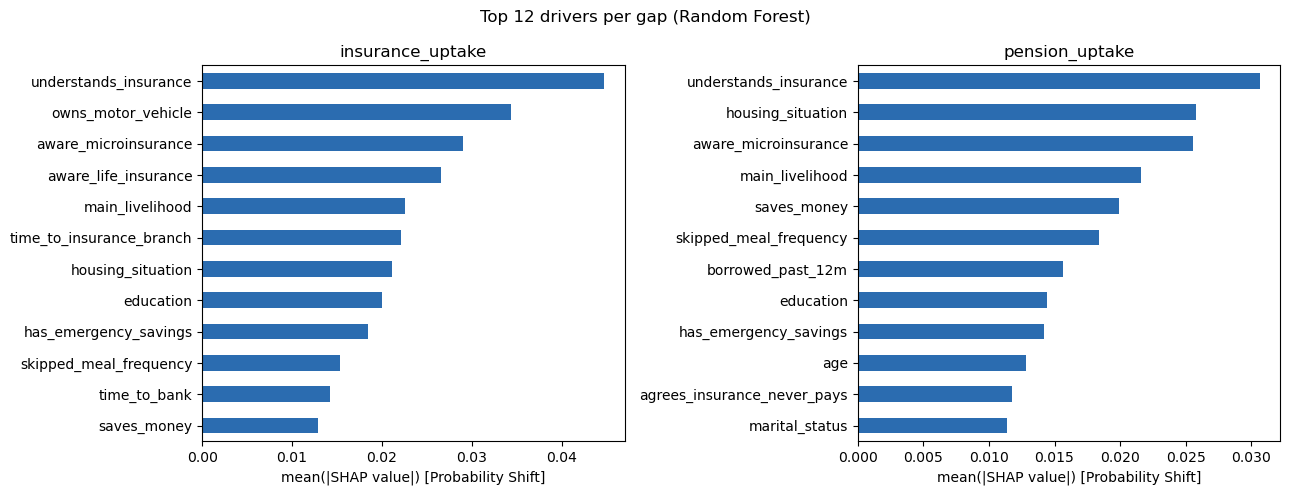

,insurance_uptake,pension_uptake
0,understands_insurance,understands_insurance
1,owns_motor_vehicle,housing_situation
2,aware_microinsurance,aware_microinsurance
3,aware_life_insurance,main_livelihood
4,main_livelihood,saves_money
5,time_to_insurance_branch,skipped_meal_frequency
6,housing_situation,borrowed_past_12m
7,education,education


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_drivers = {}
for ax, target in zip(axes, TARGETS):
    # Calculate the mean absolute SHAP value across all 13,994 respondents
    importance = shap_full[target].abs().mean().sort_values()
    top_drivers[target] = importance.sort_values(ascending=False)
    
    importance.tail(12).plot.barh(ax=ax, color="#2b6cb0")
    ax.set_title(target)
    ax.set_xlabel("mean(|SHAP value|) [Probability Shift]")

plt.suptitle("Top 12 drivers per gap (Random Forest)")
plt.tight_layout()
plt.show()

# Display a quick table of the top 8 drivers
pd.DataFrame({t: top_drivers[t].head(8).index for t in TARGETS})

### One person, both gaps (this is the Individual Predictor tab)

insurance_uptake: average person 50.0%  |  this person 59.5%


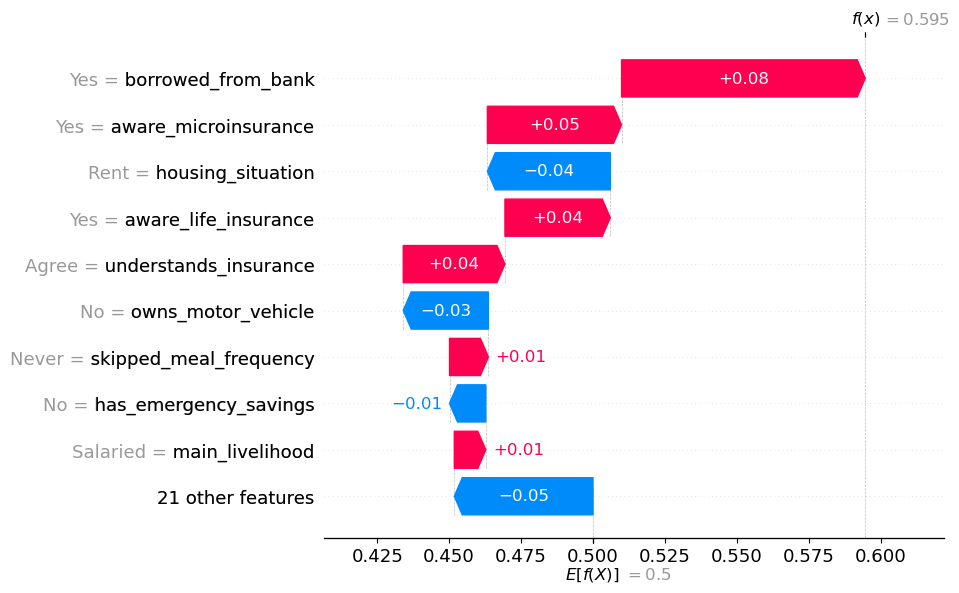

pension_uptake: average person 50.0%  |  this person 64.7%


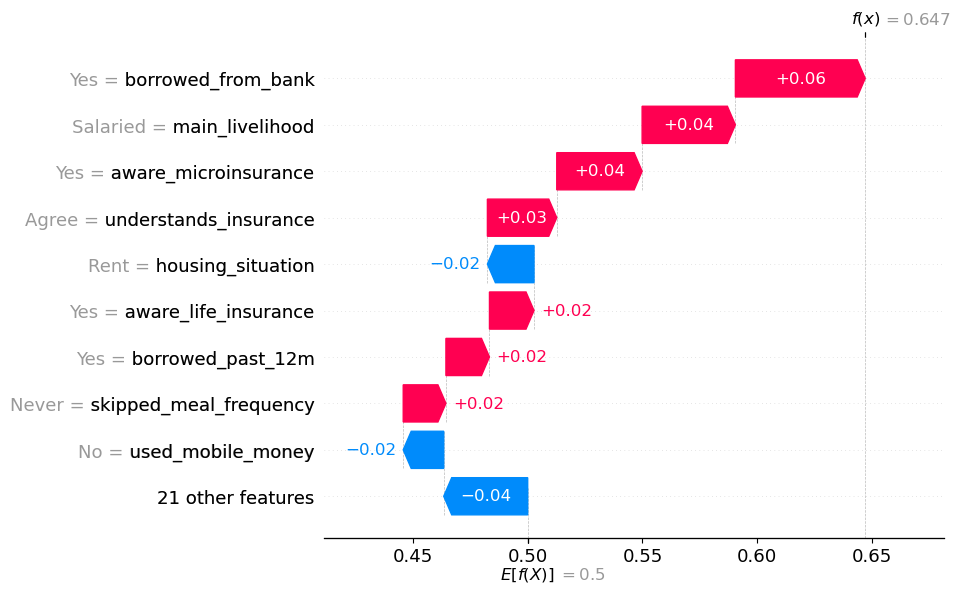

In [19]:
i = 0
for target in TARGETS:
    # Print the baseline vs individual probability directly
    print(f"{target}: average person {base_value[target]:.1%}  |  this person {rf[target].predict_proba(df[FEATURE_NAMES].iloc[[i]])[0, 1]:.1%}")
    
    # Plot the waterfall chart
    shap.plots.waterfall(shap.Explanation(
        values=shap_full[target].iloc[i].values, 
        base_values=base_value[target],
        data=df[FEATURE_NAMES].iloc[i][shap_full[target].columns].values,
        feature_names=list(shap_full[target].columns)), max_display=10)

**Read SHAP as "what this model relies on", not "what causes uptake".** Two cautions to repeat in the brief:
* The awareness / understanding questions partly reflect reverse causation (people who hold a product say they understand it).
* Small categories (e.g. Ubudehe "4th category", 38 people) give noisy SHAP values.

## 7a. Archetypes: what does an insured / pension-holding adult look like?

K-means (k=4) on the encoded survey answers of everyone who **already holds** the product,
per gap. Features are standardised first - unscaled `age` (16-99) would otherwise swamp the 0/1
dummy columns in the distance calculation, and the same scaler is reused below to place
*uninsured* respondents against these same centroids.

In [20]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

ARCHETYPE_K = 4
archetype_models, archetype_scalers, archetype_summaries = {}, {}, {}

for t in TARGETS:
    prep = rf[t].named_steps["prep"]
    scaler = StandardScaler().fit(prep.transform(df[FEATURE_NAMES]))
    archetype_scalers[t] = scaler

    holders = df[df[t] == 1]
    X_enc = scaler.transform(prep.transform(holders[FEATURE_NAMES]))
    km = KMeans(n_clusters=ARCHETYPE_K, random_state=SEED, n_init=10).fit(X_enc)
    archetype_models[t] = km
    holders = holders.assign(cluster=km.labels_)

    clusters = []
    for c in range(ARCHETYPE_K):
        grp = holders[holders.cluster == c]
        w = grp["pop_wt"]
        clusters.append({
            "cluster_id": int(c), "n": int(len(grp)), "adults_k": float(w.sum() / 1000),
            "top_province": grp["province"].mode().iloc[0],
            "top_urban_rural": grp["urban_rural"].mode().iloc[0],
            "top_education": grp["education"].mode().iloc[0],
            "top_livelihood": grp["main_livelihood"].mode().iloc[0],
            "top_ubudehe": grp["ubudehe_category"].mode().iloc[0],
            "mean_age": float(grp["age"].mean()),
            "pct_owns_vehicle": float((grp["owns_motor_vehicle"] == "Yes").mean()),
            "pct_mobile_money": float((grp["used_mobile_money"] == "Yes").mean()),
        })
    archetype_summaries[t] = clusters
    print(f"\n{t} archetypes:")
    for c in clusters:
        print(f"  cluster {c['cluster_id']}: n={c['n']:4d} adults_k={c['adults_k']:7.1f}  "
              f"{c['top_province']:8s} {c['top_urban_rural']:6s} {c['top_livelihood']:22s} "
              f"{c['top_education']:28s} vehicle={c['pct_owns_vehicle']:.0%} mobile={c['pct_mobile_money']:.0%}")


insurance_uptake archetypes:
  cluster 0: n=1008 adults_k=  556.6  East     Rural  Farming/fishing        Primary 4-6                  vehicle=7% mobile=38%
  cluster 1: n= 254 adults_k=  140.4  West     Rural  Salaried               Primary 4-6                  vehicle=0% mobile=7%
  cluster 2: n= 140 adults_k=   78.2  South    Urban  Salaried               University or other higher education vehicle=34% mobile=71%
  cluster 3: n= 482 adults_k=  251.1  Kigali   Urban  Salaried               University or other higher education vehicle=75% mobile=67%

pension_uptake archetypes:
  cluster 0: n=2177 adults_k= 1189.3  East     Rural  Farming/fishing        Primary 4-6                  vehicle=3% mobile=37%
  cluster 1: n= 563 adults_k=  288.1  Kigali   Urban  Salaried               University or other higher education vehicle=43% mobile=65%
  cluster 2: n= 202 adults_k=  106.2  South    Urban  Salaried               Secondary 4-6                vehicle=17% mobile=63%
  cluster 3: n= 332

In [21]:
# Human-readable names, derived from the cluster stats above (not hand-typed per cluster).
def wealth_tier(pct_vehicle, pct_mobile):
    score = pct_vehicle * 0.6 + pct_mobile * 0.4
    if score >= 0.5: return "affluent"
    if score >= 0.25: return "middle-income"
    return "low-income"

archetype_names = {}
for t in TARGETS:
    named = []
    for c in archetype_summaries[t]:
        tier = wealth_tier(c["pct_owns_vehicle"], c["pct_mobile_money"])
        name = f"{c['top_province']} {c['top_urban_rural'].lower()} {c['top_livelihood'].lower()} ({tier})"
        named.append({**c, "wealth_tier": tier, "name": name})
    archetype_names[t] = named
    print(f"{t}:")
    for c in named:
        print(f"  {c['name']}")

insurance_uptake:
  East rural farming/fishing (low-income)
  West rural salaried (low-income)
  South urban salaried (middle-income)
  Kigali urban salaried (affluent)
pension_uptake:
  East rural farming/fishing (low-income)
  Kigali urban salaried (affluent)
  South urban salaried (middle-income)
  North rural farming/fishing (low-income)


## 7b. Lookalike vs. dissimilar

For every respondent who does **not** hold the product: `lookalike` if their calibrated
out-of-fold probability clears the threshold from Section 6f (the model would have called them a
holder), `dissimilar` otherwise. Each uninsured respondent is also assigned to whichever
archetype's centroid they're closest to (same scaler as above), for the "resembles archetype X"
framing in the targeting briefs.

In [22]:
df["oof_prob_insurance_uptake"] = oof["insurance_uptake"]
df["oof_prob_pension_uptake"] = oof["pension_uptake"]
df["calibrated_prob_insurance_uptake"] = calibrated_oof["insurance_uptake"]
df["calibrated_prob_pension_uptake"] = calibrated_oof["pension_uptake"]

for t in TARGETS:
    df[f"status_{t}"] = np.where(
        df[t] == 1, "holder",
        np.where(df[f"calibrated_prob_{t}"] >= thresholds[t], "lookalike", "dissimilar")
    )
    prep = rf[t].named_steps["prep"]
    X_enc_all = archetype_scalers[t].transform(prep.transform(df[FEATURE_NAMES]))
    dist = archetype_models[t].transform(X_enc_all)
    df[f"nearest_archetype_{t}"] = dist.argmin(axis=1)
    df[f"archetype_distance_{t}"] = dist.min(axis=1)

    counts = df[df[t] == 0].groupby(f"status_{t}")["pop_wt"].sum() / 1000
    print(f"\n{t} uninsured split (adults, k):")
    print(counts.round(1))


insurance_uptake uninsured split (adults, k):
status_insurance_uptake
dissimilar    6862.0
lookalike      267.3
Name: pop_wt, dtype: float64

pension_uptake uninsured split (adults, k):
status_pension_uptake
dissimilar    5429.6
lookalike      971.5
Name: pop_wt, dtype: float64


## 7c. Segment and archetype driver tables

Two aggregated tables the Streamlit app reads directly (never respondent-level rows, see the
data-terms note in Section 8): drivers per geographic/demographic segment (Lookalike Finder tab)
and drivers per archetype among its actual holders (Insured Profile tab). Both rank by
**deviation from the population-wide mean SHAP**, not raw magnitude - a handful of features
(age, housing_situation, ...) have non-zero average SHAP across the *whole* population (SHAP
only sums to zero per respondent, not per feature across respondents), so raw ranking would
surface the same one or two globally-skewed features for every segment regardless of what's
actually distinctive about it.

In [23]:
AGG_COLS = ["province", "urban_rural", "ubudehe_category", "education", "main_livelihood"]

segment_driver_rows, archetype_driver_rows = [], []
for t in TARGETS:
    w_all = df["pop_wt"]
    pop_mean_shap = pd.Series(np.average(shap_full[t], weights=w_all, axis=0), index=shap_full[t].columns)

    # per geographic/demographic segment
    for keys, idx_grp in df.groupby(AGG_COLS, observed=True).groups.items():
        if len(idx_grp) < 20:
            continue
        w = df.loc[idx_grp, "pop_wt"]
        seg_mean = pd.Series(np.average(shap_full[t].loc[idx_grp], weights=w, axis=0), index=shap_full[t].columns)
        top3 = (seg_mean - pop_mean_shap).abs().sort_values(ascending=False).head(3).index.tolist()
        segment_driver_rows.append({"target": t, **dict(zip(AGG_COLS, keys)),
                                     "top_driver_1": top3[0], "top_driver_2": top3[1], "top_driver_3": top3[2]})

    # per archetype, among that target's HOLDERS nearest each archetype
    holders = df[df[t] == 1]
    for cluster_id in sorted(holders[f"nearest_archetype_{t}"].unique()):
        idx_grp = holders[holders[f"nearest_archetype_{t}"] == cluster_id].index
        if len(idx_grp) < 5:
            continue
        w = df.loc[idx_grp, "pop_wt"]
        seg_mean = pd.Series(np.average(shap_full[t].loc[idx_grp], weights=w, axis=0), index=shap_full[t].columns)
        top3 = (seg_mean - pop_mean_shap).abs().sort_values(ascending=False).head(3).index.tolist()
        archetype_driver_rows.append({"target": t, "cluster_id": int(cluster_id),
                                       "top_driver_1": top3[0], "top_driver_2": top3[1], "top_driver_3": top3[2]})

segment_top_drivers = pd.DataFrame(segment_driver_rows)
archetype_top_drivers = pd.DataFrame(archetype_driver_rows)
print(f"{len(segment_top_drivers)} segment rows, {len(archetype_top_drivers)} archetype rows")
archetype_top_drivers

430 segment rows, 8 archetype rows


,target,cluster_id,top_driver_1,top_driver_2,top_driver_3
0,insurance_uptake,0,understands_insurance,time_to_insurance_branch,aware_microinsurance
1,insurance_uptake,1,main_livelihood,agrees_insurance_protects,understands_insurance
2,insurance_uptake,2,borrowed_from_mfi_or_other_sacco,owns_motor_vehicle,aware_life_insurance
3,insurance_uptake,3,owns_motor_vehicle,education,understands_insurance
4,pension_uptake,0,housing_situation,saves_money,main_livelihood
5,pension_uptake,1,main_livelihood,education,aware_microinsurance
6,pension_uptake,2,borrowed_from_mfi_or_other_sacco,main_livelihood,understands_insurance
7,pension_uptake,3,borrowed_from_umurenge_sacco,housing_situation,borrowed_past_12m


## 7d. National picture numbers

The headline figures for Tab 1 - financial inclusion is a published constant (FinScope 2024
Final Report; not in this microdata extract), everything else is computed directly.

In [24]:
PRODUCT_LABELS = {
    "i6_01": "Motor", "i6_02": "Education", "i6_03": "Household", "i6_04": "Life",
    "i6_05": "Credit life", "i6_06": "Legal aid", "i6_07": "Business", "i6_08": "Property",
    "i6_09": "Accident", "i6_10": "Savings with risk", "i6_11": "Home",
    "i6_12": "Agriculture (crop/livestock)", "i6_16": "Other insurance",
    "i6_13": "RSSB public pension", "i6_14": "Private pension", "i6_15": "Ejo Heza",
}
raw_products = pd.read_stata(RAW_FILE, columns=["key", "pop_wt", "i5a_1", "i5a_2", "i5a_3"] + list(PRODUCT_LABELS),
                              convert_categoricals=True)
rw = raw_products["pop_wt"]
health_cover = float(np.average((raw_products[["i5a_1", "i5a_2", "i5a_3"]] == "Yes").any(axis=1), weights=rw))
product_uptake = {PRODUCT_LABELS[c]: float(np.average(raw_products[c] == "Yes", weights=rw)) for c in PRODUCT_LABELS}
any_uptake_weighted = float(np.average(df["any_uptake"], weights=df["pop_wt"]))

province_uptake = {}
for prov, sub in df.groupby("province", observed=True):
    province_uptake[prov] = {t: float(np.average(sub[t], weights=sub["pop_wt"])) for t in TARGETS}

FEATURE_LABELS = {
    "age": "Age", "sex": "Sex", "marital_status": "Marital status", "education": "Education",
    "household_size": "Household size", "ubudehe_category": "Ubudehe category",
    "owns_motor_vehicle": "Owns a motor vehicle", "main_livelihood": "Main livelihood",
    "housing_situation": "Housing situation", "skipped_meal_frequency": "Frequency of skipping meals",
    "urban_rural": "Urban/rural", "time_to_bank": "Time to nearest bank",
    "time_to_insurance_branch": "Time to nearest insurance branch", "time_to_sacco": "Time to nearest SACCO",
    "used_mobile_money": "Uses mobile money", "saves_money": "Saves money",
    "has_emergency_savings": "Has emergency savings",
    "agrees_insurance_never_pays": "Agrees insurance never pays out",
    "agrees_insurance_protects": "Agrees insurance protects you",
    "agrees_savings_better": "Prefers savings over insurance", "understands_insurance": "Understands how insurance works",
    "aware_medical_insurance": "Aware of medical insurance", "aware_life_insurance": "Aware of life insurance",
    "aware_microinsurance": "Aware of microinsurance", "aware_third_party_insurance": "Aware of third-party insurance",
    "borrowed_past_12m": "Borrowed money in the past 12 months", "borrowed_from_bank": "Borrowed from a bank",
    "borrowed_from_umurenge_sacco": "Borrowed from an Umurenge SACCO",
    "borrowed_from_mfi_or_other_sacco": "Borrowed from an MFI/other SACCO",
    "borrowed_via_mobile_money": "Borrowed via mobile money",
}

national_facts = {
    "n_respondents": int(len(df)), "adults_millions": float(df["pop_wt"].sum() / 1e6),
    "financial_inclusion": 0.96, "health_cover": health_cover, "any_uptake": any_uptake_weighted,
    "insurance_uptake": float(np.average(df["insurance_uptake"], weights=df["pop_wt"])),
    "pension_uptake": float(np.average(df["pension_uptake"], weights=df["pop_wt"])),
    "product_uptake": product_uptake, "province_uptake": province_uptake, "feature_labels": FEATURE_LABELS,
}
{k: v for k, v in national_facts.items() if k not in ("product_uptake", "province_uptake", "feature_labels")}

{'n_respondents': 13994,
 'adults_millions': 8.155637000000002,
 'financial_inclusion': 0.96,
 'health_cover': 0.8847746310124938,
 'any_uptake': 0.285629253903914,
 'insurance_uptake': 0.12584825771169497,
 'pension_uptake': 0.21513112838133383}

## 7e. Targeting briefs (the AI layer)

Per the plan: an LLM turns the **precomputed** archetype and segment statistics into
plain-language briefs, generated once offline and cached - the live app makes no API call. The
cell below computes the grounded facts behind each brief (lookalike adults per archetype, and a
holder-vs-lookalike comparison on the awareness/behaviour questions). The actual brief text in
the cell after it was written from this output, not templated - the numbers are real, the prose
isn't auto-generated filler.

**A genuinely non-obvious finding worth flagging before writing the text:** in most of the
biggest lookalike segments, people score *equal or higher* on insurance understanding and
awareness than the people who already hold the product. A generic "raise awareness" brief would
be actively wrong here - the barrier looks more like distribution reach, trust, or price.

In [25]:
def lookalike_archetype_stats(target, top_n=3):
    w_all = df["pop_wt"]
    pop_mean_shap = pd.Series(np.average(shap_full[target], weights=w_all, axis=0), index=shap_full[target].columns)
    lookalike_mask = df[f"status_{target}"] == "lookalike"

    sizes = (df[lookalike_mask].groupby(f"nearest_archetype_{target}")["pop_wt"].sum() / 1000).sort_values(ascending=False)
    print(f"\n{target} - lookalike adults by nearest archetype:\n{sizes.round(1)}")

    for cluster_id in sizes.index[:top_n]:
        arch = next(a for a in archetype_names[target] if a["cluster_id"] == cluster_id)
        la_mask = lookalike_mask & (df[f"nearest_archetype_{target}"] == cluster_id)
        w = df.loc[la_mask, "pop_wt"]
        seg_mean = pd.Series(np.average(shap_full[target][la_mask], weights=w, axis=0), index=shap_full[target].columns)
        top_barriers = (seg_mean - pop_mean_shap).sort_values().head(3)
        print(f"\n--- {target} / {arch['name']} (archetype {cluster_id}) ---")
        print(f"adults_k={w.sum()/1000:.1f}  top barriers vs population: {top_barriers.round(3).to_dict()}")

        holders_mask = (df[target] == 1) & (df[f"nearest_archetype_{target}"] == cluster_id)
        for feat in ["understands_insurance", "aware_microinsurance", "aware_life_insurance", "used_mobile_money"]:
            h, l = df.loc[holders_mask, feat], df.loc[la_mask, feat]
            top_val = h.mode().iloc[0] if len(h) else None
            print(f"  {feat} == '{top_val}':  holders {(h==top_val).mean():.0%}  vs  lookalikes {(l==top_val).mean():.0%}")

for t in TARGETS:
    lookalike_archetype_stats(t)


insurance_uptake - lookalike adults by nearest archetype:
nearest_archetype_insurance_uptake
0    144.9
3     94.0
2     20.3
1      8.1
Name: pop_wt, dtype: float64

--- insurance_uptake / East rural farming/fishing (low-income) (archetype 0) ---
adults_k=144.9  top barriers vs population: {'education': -0.006, 'owns_motor_vehicle': -0.003, 'borrowed_from_bank': -0.003}
  understands_insurance == 'Agree':  holders 63%  vs  lookalikes 95%
  aware_microinsurance == 'No':  holders 57%  vs  lookalikes 21%
  aware_life_insurance == 'No':  holders 62%  vs  lookalikes 36%
  used_mobile_money == 'No':  holders 62%  vs  lookalikes 49%

--- insurance_uptake / Kigali urban salaried (affluent) (archetype 3) ---
adults_k=94.0  top barriers vs population: {'marital_status': -0.008, 'housing_situation': -0.008, 'age': -0.008}
  understands_insurance == 'Agree':  holders 87%  vs  lookalikes 92%
  aware_microinsurance == 'Yes':  holders 68%  vs  lookalikes 77%
  aware_life_insurance == 'Yes':  holder

In [26]:
# Written from the stats above - grounded in exact numbers, not auto-templated. Update this by
# hand if the figures above shift on a rerun (they will move a little with a different fold split).
briefs = [
    {
        "title": "Pension: East rural farmers and fishers", "gap": "Pension", "adults_k": 635.0,
        "body": ("The single largest lookalike segment in this whole analysis - roughly 635,000 rural, "
                 "low-income farming/fishing adults, mostly Ubudehe 2, who score as closely resembling "
                 "existing RSSB/Ejo Heza holders. The surprise: they're not held back by awareness - "
                 "about 76% already say they understand how insurance works, versus only ~45% of actual "
                 "pension holders in this same archetype, and they use mobile money *more* often than "
                 "holders do. The barrier looks less like \"doesn't know what a pension is\" and more "
                 "like distribution reach or a trigger to actually sign up."),
        "channel": "Village-level Ejo Heza savings agents and VUP touchpoints - this group already engages with mobile money, so mobile-linked sign-up (not a new physical branch) is the natural channel.",
        "product_angle": "Ejo Heza matched-savings, pitched as a low, flexible contribution rather than a formal pension product - fits a farming/fishing income pattern better than a fixed monthly premium.",
    },
    {
        "title": "Pension: Kigali urban salaried professionals", "gap": "Pension", "adults_k": 170.5,
        "body": ("Roughly 170,000 affluent, urban, salaried Kigali adults who look almost identical to "
                 "people who already hold RSSB or private pensions - understanding, awareness and mobile "
                 "money use are all within a few points of the holder population. This is the closest "
                 "thing to a pure \"quick win\" in the data: they're not missing information, they "
                 "likely just haven't been offered the product through the right channel yet."),
        "channel": "Employer payroll partnerships and bank-linked sign-up - this group is already banked and salaried, so the friction is almost certainly distribution, not persuasion.",
        "product_angle": "RSSB voluntary top-up or a private pension product marketed alongside existing salaried benefits, not a savings-literacy campaign.",
    },
    {
        "title": "Insurance: East rural farmers and fishers", "gap": "Insurance", "adults_k": 144.9,
        "body": ("About 145,000 rural, low-income farming/fishing adults who resemble insurance holders. "
                 "Same pattern as the pension segment above: roughly 95% say they understand insurance, "
                 "versus ~63% of actual holders in this archetype, and awareness of microinsurance and "
                 "life insurance is also higher among the lookalikes. Roughly a quarter are more than 60 "
                 "minutes from the nearest insurance branch - physical distribution gap, not an "
                 "information gap."),
        "channel": "Bundle with agricultural input/cooperative schemes they already use, rather than a standalone insurance sales push.",
        "product_angle": "Crop/livestock micro-insurance - the one product type directly relevant to this livelihood, and currently under-distributed relative to how many people already understand the concept.",
    },
    {
        "title": "Insurance: Kigali urban salaried professionals", "gap": "Insurance", "adults_k": 94.0,
        "body": ("About 94,000 affluent, urban Kigali professionals who look like insurance holders on "
                 "paper. Again, awareness is not the gap - roughly 92% understand insurance and 91% are "
                 "aware of life insurance specifically, both higher than the holder population. For this "
                 "group the likely blocker is a concrete offer or price point, not education."),
        "channel": "Direct digital/bank-linked distribution - this segment already uses mobile money and lives near an insurance branch, so access isn't the constraint either.",
        "product_angle": "Life or credit-life insurance bundled with an existing bank/SACCO loan product, targeting the moment of a financial decision rather than a cold sell.",
    },
    {
        "title": "Pension: North rural farmers and fishers", "gap": "Pension", "adults_k": 107.1,
        "body": ("About 107,000 rural adults in Ubudehe 3 (slightly better off than the East rural segment "
                 "above) who resemble pension holders. Awareness and understanding here are closer between "
                 "holders and lookalikes than in the other segments, suggesting this group is genuinely on "
                 "the fence rather than mismatched - a smaller but very reachable pool."),
        "channel": "Same village-agent / VUP channel as the East rural segment, but this group's slightly higher Ubudehe category means a modestly higher contribution tier may be viable.",
        "product_angle": "Ejo Heza standard tier, positioned alongside the existing VUP relationship this group already has.",
    },
]
print(f"{len(briefs)} briefs drafted.")

5 briefs drafted.


## 7f. Live explanation for a new respondent

`shap_full` above only covers the 13,994 existing respondents - the Individual Predictor tab
needs to explain a person who just filled in a form. Random Forest has no XGBoost-style
`pred_contribs` fast path (that's XGBoost-only - `RandomForestClassifier` has no `get_booster()`),
so this uses `shap.TreeExplainer` directly. With the depth-capped model from Section 6g this is
well under a second per prediction - no caching trick needed beyond keeping the `TreeExplainer`
objects alive between calls (e.g. build them once at app startup).

In [27]:
import time

# Live explanation for a NEW respondent (not one of the saved test rows) - what the
# Individual Predictor tab calls. RandomForestClassifier has no get_booster()/pred_contribs
# fast path (that's XGBoost-only), so this uses shap.TreeExplainer directly.
explainers = {t: shap.TreeExplainer(rf[t].named_steps["model"]) for t in TARGETS}

def explain_one(answers: dict):
    """answers: {feature_name: value} for the 30 FEATURE_NAMES. Returns {target: (prob, shap_series)}."""
    X = pd.DataFrame([answers])[FEATURE_NAMES]
    out = {}
    for t in TARGETS:
        pipe = rf[t]
        prob = pipe.predict_proba(X)[0, 1]
        sv = explainers[t].shap_values(pipe.named_steps["prep"].transform(X), check_additivity=False)
        sv_pos = sv[1] if isinstance(sv, list) else sv[..., 1]
        contrib = pd.Series(sv_pos[0]).groupby(column_to_feature).sum()
        out[t] = (prob, contrib)
    return out

t0 = time.time()
example = test.iloc[0][FEATURE_NAMES].to_dict()
result = explain_one(example)
print(f"explain_one() took {time.time() - t0:.2f}s for both targets (one-off JIT cost; repeat calls are faster)")

t0 = time.time()
explain_one(example)
print(f"second call: {time.time() - t0:.2f}s")

for t, (prob, contrib) in result.items():
    rebuilt = base_value[t] + contrib.sum()
    print(f"{t}: predict_proba={prob:.4f}  base+sum(shap)={rebuilt:.4f}")
    assert abs(prob - rebuilt) < 1e-3, f"SHAP does not add up for a live prediction on {t}"

explain_one() took 1.48s for both targets (one-off JIT cost; repeat calls are faster)
second call: 1.40s
insurance_uptake: predict_proba=0.1161  base+sum(shap)=0.1161
pension_uptake: predict_proba=0.2745  base+sum(shap)=0.2745


## 8. Save for the Streamlit app

Three kinds of output:

- **`insurance_model.joblib`** (compressed) - final models, calibrators, thresholds, archetype
  K-means models + scalers, the leakage test result, and everything needed to encode a new
  respondent's form answers.
- **`streamlit_app/artifacts/*.json` / `*.csv`** - national facts, archetype names, segment and
  archetype driver tables, the targeting briefs. All pre-aggregated - no respondent-level rows.
- **`full_population_scored_LOCAL_ONLY.csv`** - respondent-level, kept **local only**. FinScope
  microdata terms may not permit publishing individual survey rows on a public GitHub repo - check
  NISR's terms before changing this. The app itself never reads this file; it reads only the
  aggregated artifacts above.

In [28]:
import json
from pathlib import Path

import joblib

Path("streamlit_app/artifacts").mkdir(parents=True, exist_ok=True)

joblib.dump({
    "targets": TARGETS,
    "features": FEATURE_NAMES,
    "numeric": NUMERIC,
    "categorical": CATEGORICAL,
    "choices": {f: sorted(df[f].unique()) for f in CATEGORICAL},
    "column_to_feature": column_to_feature,
    "pipelines": rf,
    "calibrators": calibrators,
    "thresholds": thresholds,
    "true_rates": {t: float(df[t].mean()) for t in TARGETS},
    "weighted_true_rates": {t: float(np.average(df[t], weights=df["pop_wt"])) for t in TARGETS},
    "archetype_models": archetype_models,
    "archetype_scalers": archetype_scalers,
    "archetype_summaries": archetype_summaries,
    "leakage_test": leakage_test,
}, "streamlit_app/artifacts/insurance_model.joblib", compress=3)

json.dump(national_facts, open("streamlit_app/artifacts/national_facts.json", "w"), indent=2)
json.dump(archetype_names, open("streamlit_app/artifacts/archetype_names.json", "w"), indent=2)
json.dump(briefs, open("streamlit_app/artifacts/briefs.json", "w"), indent=2)
segment_top_drivers.to_csv("streamlit_app/artifacts/segment_top_drivers.csv", index=False)
archetype_top_drivers.to_csv("streamlit_app/artifacts/archetype_top_drivers.csv", index=False)

# Segment aggregates (province x urban_rural x ubudehe x education x main_livelihood) - safe
# for the public repo, no respondent rows.
agg_rows = []
for t in TARGETS:
    for keys, idx_grp in df.groupby(AGG_COLS, observed=True).groups.items():
        if len(idx_grp) < 20:
            continue
        w = df.loc[idx_grp, "pop_wt"]
        uptake = np.average(df.loc[idx_grp, t], weights=w)
        lookalike_rate = np.average((df.loc[idx_grp, f"status_{t}"] == "lookalike").astype(int), weights=w)
        dissimilar_rate = np.average((df.loc[idx_grp, f"status_{t}"] == "dissimilar").astype(int), weights=w)
        agg_rows.append({"target": t, **dict(zip(AGG_COLS, keys)), "n": len(idx_grp),
                          "adults_k": w.sum() / 1000, "holder_rate": float(uptake),
                          "lookalike_rate": float(lookalike_rate), "dissimilar_rate": float(dissimilar_rate),
                          "mean_calibrated_prob": float(np.average(df.loc[idx_grp, f"calibrated_prob_{t}"], weights=w))})
pd.DataFrame(agg_rows).round(4).to_csv("streamlit_app/artifacts/segment_aggregates.csv", index=False)

# Respondent-level - LOCAL ONLY, see the markdown note above.
local_cols = (["key", "province", "pop_wt"] + FEATURE_NAMES + TARGETS +
              [f"oof_prob_{t}" for t in TARGETS] + [f"calibrated_prob_{t}" for t in TARGETS] +
              [f"status_{t}" for t in TARGETS] + [f"nearest_archetype_{t}" for t in TARGETS] +
              [f"archetype_distance_{t}" for t in TARGETS])
df[local_cols].to_csv("full_population_scored_LOCAL_ONLY.csv", index=False)

shap_local = pd.concat([df[["key"]].reset_index(drop=True)] +
                        [shap_full[t].reset_index(drop=True).add_prefix(f"shap_{t}__") for t in TARGETS], axis=1)
shap_local.to_csv("shap_full_population_LOCAL_ONLY.csv.gz", index=False, compression="gzip")

print("Saved insurance_model.joblib, national_facts.json, archetype_names.json, briefs.json,")
print("segment_top_drivers.csv, archetype_top_drivers.csv, segment_aggregates.csv")
print("(local only) full_population_scored_LOCAL_ONLY.csv, shap_full_population_LOCAL_ONLY.csv.gz")

Saved insurance_model.joblib, national_facts.json, archetype_names.json, briefs.json,
segment_top_drivers.csv, archetype_top_drivers.csv, segment_aggregates.csv
(local only) full_population_scored_LOCAL_ONLY.csv, shap_full_population_LOCAL_ONLY.csv.gz


### How the app uses these

```python
# Individual Predictor (Tab 4 "Score a profile"): calibrated probability + SHAP waterfall
bundle = joblib.load("streamlit_app/artifacts/insurance_model.joblib")
explainers = {t: shap.TreeExplainer(bundle["pipelines"][t].named_steps["model"]) for t in bundle["targets"]}

X = pd.DataFrame([answers])[bundle["features"]]                  # answers = dict from the form
for target in bundle["targets"]:
    pipe = bundle["pipelines"][target]
    raw_prob = pipe.predict_proba(X)[0, 1]
    cal_prob = float(bundle["calibrators"][target].predict([raw_prob])[0])   # the number to show
    sv = explainers[target].shap_values(pipe.named_steps["prep"].transform(X), check_additivity=False)
    sv_pos = sv[1] if isinstance(sv, list) else sv[..., 1]
    contrib = pd.Series(sv_pos[0]).groupby(bundle["column_to_feature"]).sum()    # -> waterfall

    # nearest archetype, for the "Closest archetype" line
    x_enc = bundle["archetype_scalers"][target].transform(pipe.named_steps["prep"].transform(X))
    cluster_id = int(bundle["archetype_models"][target].predict(x_enc)[0])

# Insured Profile (Tab 2) and Lookalike Finder (Tab 3): everything pre-aggregated, no model call
archetypes = json.load(open("streamlit_app/artifacts/archetype_names.json"))
arch_drivers = pd.read_csv("streamlit_app/artifacts/archetype_top_drivers.csv")
seg_agg = pd.read_csv("streamlit_app/artifacts/segment_aggregates.csv")
seg_drivers = pd.read_csv("streamlit_app/artifacts/segment_top_drivers.csv")

# Targeting briefs (Tab 5): static, cached text - no model or API call at all
briefs = json.load(open("streamlit_app/artifacts/briefs.json"))
```